# Giorno 2 — Preprocessing e valutazione dei classificatori

> Linguaggio degli esempi: Python 3 (scikit-learn ≥ 1.4, NumPy, pandas, matplotlib, seaborn). Ogni modulo segue la struttura: Spiegazione teorica → Esempi teorici di utilizzo → Esempi di codice → Esercizi.
> Collegamento con il Giorno 1: alla fine del modulo 1.5 KNN otteneva solo 0.72 di accuratezza su Wine. Oggi vediamo perché e come risolvere.

# 2.1 Scaling delle feature: standardizzazione e normalizzazione

## Spiegazione teorica

**Il problema: feature su scale diverse**
- Nel dataset Wine `proline` va da circa 280 a 1680, mentre `nonflavanoid_phenols` va da 0.13 a 0.66.
- Per KNN la distanza tra due vini è quasi tutta determinata da `proline`: una differenza di 100 in proline "pesa" infinitamente più di una differenza di 0.3 nei fenoli, anche se i fenoli potrebbero essere più utili.
- Lo **scaling** porta tutte le feature su scale confrontabili, così nessuna domina per il solo fatto di avere numeri più grandi.

**Due concetti statistici necessari**
- **Media:** somma dei valori diviso il loro numero.
- **Deviazione standard:** quanto, in media, i valori si allontanano dalla media. Piccola → valori concentrati; grande → valori sparsi. La **varianza** è la deviazione standard al quadrato.

**Standardizzazione — `StandardScaler`**
- Formula: `z = (x − media) / deviazione_standard`, calcolata **colonna per colonna**.
- Risultato: ogni feature ha media 0 e deviazione standard 1 (varianza unitaria). I valori si leggono come "quante deviazioni standard sopra o sotto la media".
- È la scelta di default nella maggior parte dei casi.
- Parametri: `with_mean` (default True, centra sulla media), `with_std` (default True, divide per la dev. standard), `copy` (default True, non modifica i dati originali).

**Normalizzazione — `MinMaxScaler`**
- Formula: `x' = (x − min) / (max − min)` → ogni feature va da 0 a 1.
- Utile quando serve un intervallo fisso (es. intensità dei pixel, reti neurali).
- Sensibile agli **outlier** (valori anomali molto lontani dagli altri): un solo valore enorme schiaccia tutti gli altri vicino a 0.
- Alternativa robusta: `RobustScaler` usa mediana e intervallo interquartile, poco influenzati dagli outlier.

**Quali modelli ne hanno bisogno**
- Sì: modelli basati su **distanze** (KNN, SVM, K-Means), su **gradienti** (regressione logistica, reti neurali), PCA.
- No: **alberi di decisione** e modelli basati su alberi (Random Forest, Gradient Boosting): confrontano una feature alla volta con una soglia, quindi la scala non cambia le loro decisioni.

**I transformer di scikit-learn: `fit`, `transform`, `fit_transform`**
- Gli scaler non sono modelli ma **transformer**: oggetti che trasformano i dati.
- `fit(X)` → **impara** le statistiche (media, dev. standard, min, max). Le salva in attributi: `mean_`, `scale_`, `data_min_`, `data_max_`.
- `transform(X)` → **applica** la trasformazione usando le statistiche imparate.
- `fit_transform(X)` → le due cose insieme, in un solo passaggio.
- `inverse_transform(X)` → riporta i valori alla scala originale.
- L'output è un array NumPy; con `scaler.set_output(transform="pandas")` si ottiene un DataFrame con i nomi delle colonne.

## Esempi teorici di utilizzo

- **KNN o SVM su dati clinici:** età (20–90), colesterolo (100–300), indice di massa corporea (15–40): senza scaling il colesterolo decide quasi da solo chi sono i "vicini".
- **Pixel di un'immagine:** valori 0–255 portati in 0–1 con MinMax prima di una rete neurale.
- **Dati con outlier (stipendi, prezzi di case):** pochi valori enormi rovinerebbero il MinMax; si preferisce StandardScaler o RobustScaler.
- **Albero di decisione:** si può saltare lo scaling, ma non fa danni; spesso lo si applica comunque per poter confrontare più modelli con la stessa preparazione dei dati.

## Esempi di codice

### Base
Cosa mostra: cosa fa davvero `StandardScaler` su una piccola tabella.

In [8]:
import numpy as np
from sklearn.preprocessing import StandardScaler

np.set_printoptions(suppress=True, precision=2)

X = np.array([[1000, 0.5],
              [1500, 0.2],
              [ 500, 0.8]])               # due feature su scale molto diverse

scaler = StandardScaler()
X_std = scaler.fit_transform(X)           # impara media e dev. standard, poi trasforma

print("Medie imparate:", scaler.mean_)        # [1000. 0.5]
print("Dev. standard:", scaler.scale_.round(3))
print(X_std.round(2))                         # ora le due colonne sono confrontabili
print("Nuove medie:", X_std.mean(axis=0).round(2))   # [0. 0.]
print("Nuove dev. std:", X_std.std(axis=0).round(2)) # [1. 1.]

Medie imparate: [1000.     0.5]
Dev. standard: [408.25   0.24]
[[ 0.    0.  ]
 [ 1.22 -1.22]
 [-1.22  1.22]]
Nuove medie: [0. 0.]
Nuove dev. std: [1. 1.]


- `fit_transform` calcola le statistiche per **ogni colonna** separatamente.
- Dopo la trasformazione le due feature hanno media 0 e dev. standard 1.
- Il valore 1500 diventa positivo (sopra la media), 500 negativo (sotto la media).

### Intermedio
Cosa mostra: differenza tra standardizzazione e normalizzazione in presenza di un outlier.

In [12]:
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

stipendi = np.array([[1800], [2100], [2400], [2000],[25000]])   # l'ultimo è un outlier

minmax = MinMaxScaler().fit(stipendi)
standard = StandardScaler().fit(stipendi)

print("MinMax:  ", minmax.transform(stipendi).ravel().round(3))     # i "normali" finiscono vicino a 0
print("Standard:", standard.transform(stipendi).ravel().round(3))

originali = minmax.inverse_transform(minmax.transform(stipendi))    # torniamo indietro
print("Ricostruiti:", originali.ravel())

MinMax:   [0.   0.01 0.03 0.01 1.  ]
Standard: [-0.53 -0.5  -0.46 -0.51  2.  ]
Ricostruiti: [ 1800.  2100.  2400.  2000. 25000.]


- Con MinMax i 4 stipendi normali finiscono tutti tra 0 e 0.03: l'outlier occupa quasi tutto l'intervallo 0–1.
- Anche StandardScaler è influenzato dall'outlier (che alza media e dev. standard), ma non costringe i valori in un intervallo fisso.
- `inverse_transform` serve per rileggere i risultati nelle unità originali.
- `ravel()` trasforma la colonna in un vettore semplice per una stampa più leggibile.

### Avanzato
Cosa mostra: l'effetto dello scaling su KNN nel dataset Wine (il caso del Giorno 1).

Senza scaling: 0.72
Con scaling:   0.94


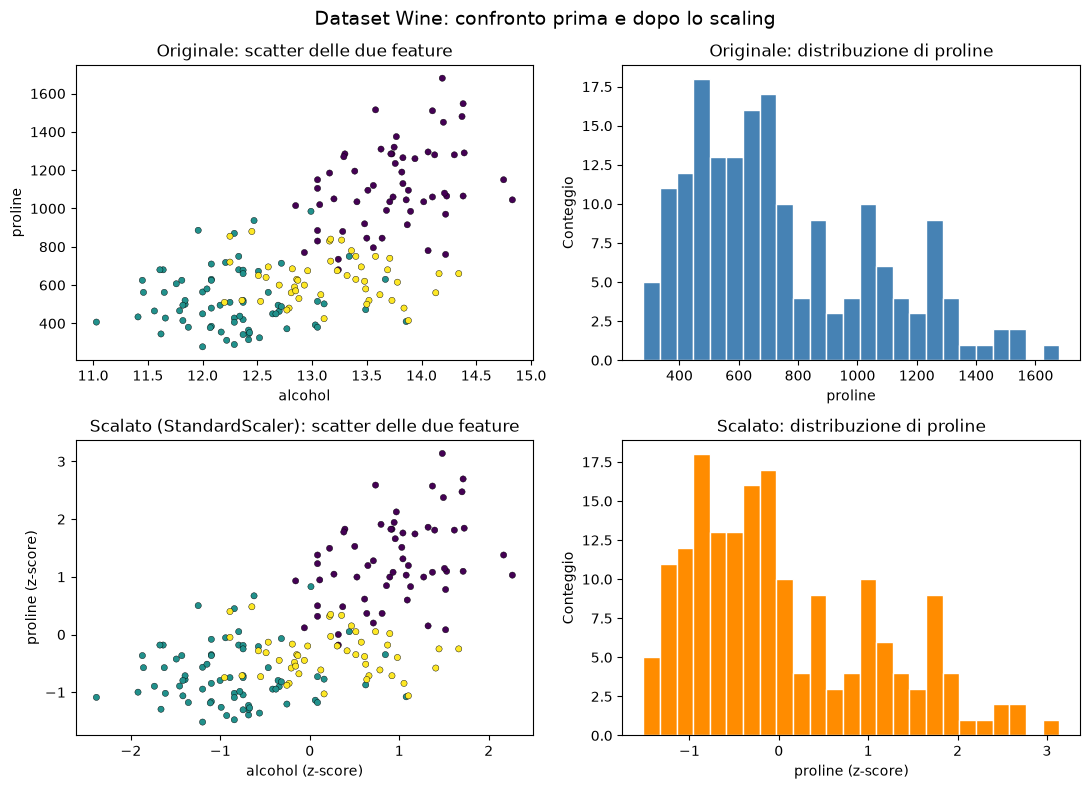

In [13]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt

X, y = load_wine(return_X_y=True)
feature_names = load_wine().feature_names
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Senza scaling
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
print("Senza scaling:", round(knn.score(X_test, y_test), 2))      # 0.72

# Con scaling: fit SOLO sul training (perché lo vediamo nel modulo 2.2)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s = scaler.transform(X_test)                                # stesse statistiche del training
knn_s = KNeighborsClassifier(n_neighbors=5).fit(X_train_s, y_train)
print("Con scaling:  ", round(knn_s.score(X_test_s, y_test), 2))   # 0.94

# ---- Grafico: confronto prima e dopo lo scaling ----
# Lo scaler è stato fittato sul training, quindi lo applichiamo a tutto X
# per visualizzare l'intero dataset nello spazio scalato.
X_s = scaler.transform(X)

# Due feature a confronto: alcol (indice 0) e proline (indice 12)
idx_a, idx_b = 0, 12

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

# Riga 1: dati originali
axes[0, 0].scatter(X[:, idx_a], X[:, idx_b], c=y, cmap="viridis", s=20, edgecolor="k", linewidth=0.3)
axes[0, 0].set_title("Originale: scatter delle due feature")
axes[0, 0].set_xlabel(feature_names[idx_a])
axes[0, 0].set_ylabel(feature_names[idx_b])

axes[0, 1].hist(X[:, idx_b], bins=25, color="steelblue", edgecolor="white")
axes[0, 1].set_title(f"Originale: distribuzione di {feature_names[idx_b]}")
axes[0, 1].set_xlabel(feature_names[idx_b])
axes[0, 1].set_ylabel("Conteggio")

# Riga 2: dati scalati
axes[1, 0].scatter(X_s[:, idx_a], X_s[:, idx_b], c=y, cmap="viridis", s=20, edgecolor="k", linewidth=0.3)
axes[1, 0].set_title("Scalato (StandardScaler): scatter delle due feature")
axes[1, 0].set_xlabel(f"{feature_names[idx_a]} (z-score)")
axes[1, 0].set_ylabel(f"{feature_names[idx_b]} (z-score)")

axes[1, 1].hist(X_s[:, idx_b], bins=25, color="darkorange", edgecolor="white")
axes[1, 1].set_title(f"Scalato: distribuzione di {feature_names[idx_b]}")
axes[1, 1].set_xlabel(f"{feature_names[idx_b]} (z-score)")
axes[1, 1].set_ylabel("Conteggio")

fig.suptitle("Dataset Wine: confronto prima e dopo lo scaling", fontsize=14)
fig.tight_layout()
plt.show()

- Stesso modello, stessi dati, stesso k: cambia solo la scala delle feature e l'accuratezza passa da 0.72 a 0.94.
- Lo scaler viene "addestrato" sul training e poi applicato a entrambi gli insiemi.
- Questo è il motivo per cui KNN era l'ultimo nel confronto del modulo 1.5.

### Extra
Cosa mostra: la deviazione standard calcolata passo per passo su due classi con la stessa media ma dispersione diversa.

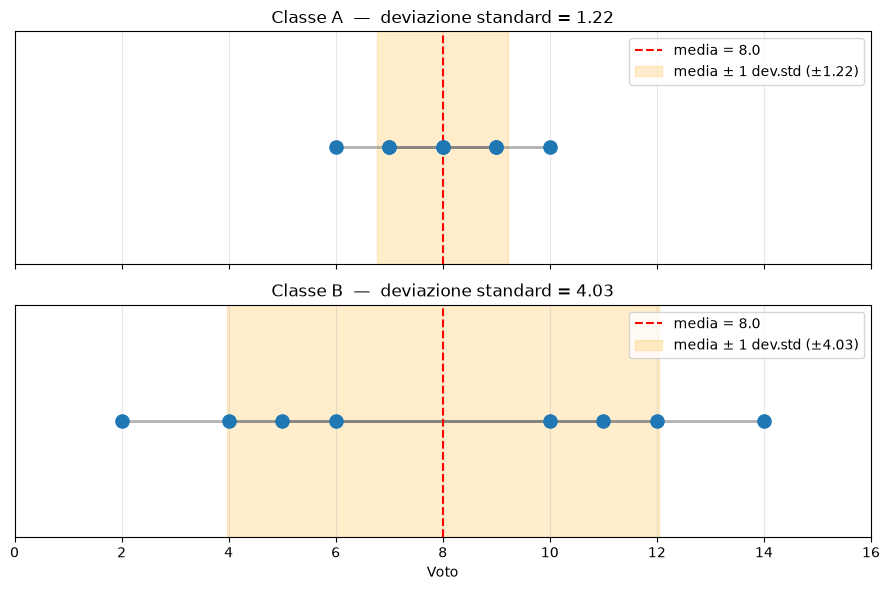


--- Classe A ---
valori  : [ 6  7  7  8  8  9  9 10]
scarti  : [-2. -1. -1.  0.  0.  1.  1.  2.]
quadrati: [4. 1. 1. 0. 0. 1. 1. 4.] -> somma = 12.0
varianza = 12.0 / 8 = 1.5
dev.std  = sqrt(1.5) = 1.2247
controllo con numpy: 1.2247

--- Classe B ---
valori  : [ 2  4  5  6 10 11 12 14]
scarti  : [-6. -4. -3. -2.  2.  3.  4.  6.]
quadrati: [36. 16.  9.  4.  4.  9. 16. 36.] -> somma = 130.0
varianza = 130.0 / 8 = 16.25
dev.std  = sqrt(16.25) = 4.0311
controllo con numpy: 4.0311


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

classe_A = np.array([6, 7, 7, 8, 8, 9, 9, 10])     
classe_B = np.array([2, 4, 5, 6, 10, 11, 12, 14])  

def passi_std(dati):
    media = dati.mean()
    scarti = dati - media              # 1. scarto dalla media
    quadrati = scarti ** 2             # 2. al quadrato
    varianza = quadrati.mean()         # 3. media dei quadrati
    dev_std = np.sqrt(varianza)        # 4. radice quadrata
    return media, scarti, quadrati, varianza, dev_std

def disegna(ax, dati, nome):
    media, _, _, _, dev = passi_std(dati)
    # segmento grigio = scarto di ogni valore rispetto alla media
    for v in dati:
        ax.plot([media, v], [0, 0], color='gray', lw=2, alpha=.6)
    ax.scatter(dati, np.zeros(len(dati)), s=90, color='tab:blue', zorder=3)
    ax.axvline(media, color='red', ls='--', label=f'media = {media:.1f}')
    # fascia arancione = media ± 1 deviazione standard
    ax.axvspan(media - dev, media + dev, color='orange', alpha=.2,
               label=f'media ± 1 dev.std (±{dev:.2f})')
    ax.set_title(f'{nome}  —  deviazione standard = {dev:.2f}')
    ax.set_yticks([])
    ax.set_xlim(0, 16)
    ax.grid(axis='x', alpha=.3)
    ax.legend(loc='upper right')

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
disegna(axes[0], classe_A, 'Classe A')
disegna(axes[1], classe_B, 'Classe B')
axes[1].set_xlabel('Voto')
plt.tight_layout()
plt.show()

# Calcolo passo per passo, da far vedere agli studenti
for nome, dati in [('A', classe_A), ('B', classe_B)]:
    media, scarti, quadrati, var, dev = passi_std(dati)
    print(f'\n--- Classe {nome} ---')
    print('valori  :', dati)
    print('scarti  :', scarti)
    print('quadrati:', quadrati, '-> somma =', quadrati.sum())
    print(f'varianza = {quadrati.sum()} / {len(dati)} = {var}')
    print(f'dev.std  = sqrt({var}) = {dev:.4f}')
    print('controllo con numpy:', round(dati.std(), 4))


- Le due classi hanno la stessa media (8), ma la classe B è molto più dispersa: la deviazione standard lo misura (≈1.2 contro ≈4.0).
- La funzione `passi_std` segue la definizione in 4 passi: scarto, quadrato, media dei quadrati (varianza), radice.
- La fascia arancione mostra l'intervallo media ± 1 dev.std: in entrambe le classi cadono 6 valori su 8, ma nella classe B quelli esterni sono molto più lontani.
- `dati.std()` di NumPy usa la stessa formula (divisione per n), quindi il controllo finale deve dare lo stesso risultato.

## Esercizi

### Facile
Obiettivo: su `load_breast_cancer()` stampa minimo e massimo di ogni feature (con pandas `describe()` o NumPy) e individua le due feature con la scala più grande e più piccola. Poi applica `MinMaxScaler` e verifica che ora tutte vadano da 0 a 1.

In [ ]:
# Scrivi qui la tua soluzione
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

cancer = load_breast_cancer()
arr = cancer.data

range_feature = arr.max(axis=0) - arr.min(axis=0)

print("Feature con scala più grande:", cancer.feature_names[range_feature.argmax()])
print("----------------------------------------")
print("Feature con scala più piccola:", cancer.feature_names[range_feature.argmin()])
print("----------------------------------------")



df = pd.DataFrame(arr, columns=cancer.feature_names)
print(df.describe())

print("----------------------------------------")

minmax = MinMaxScaler()
arr_scaled = minmax.fit_transform(arr)

print("Minimi scalati:", arr_scaled.min(axis=0).round(3))

print("----------------------------------------")

print("Massimi scalati:", arr_scaled.max(axis=0).round(3))


Feature con scala più grande: worst area
----------------------------------------
Feature con scala più piccola: fractal dimension error
----------------------------------------
       mean radius  mean texture  mean perimeter    mean area  \
count   569.000000    569.000000      569.000000   569.000000   
mean     14.127292     19.289649       91.969033   654.889104   
std       3.524049      4.301036       24.298981   351.914129   
min       6.981000      9.710000       43.790000   143.500000   
25%      11.700000     16.170000       75.170000   420.300000   
50%      13.370000     18.840000       86.240000   551.100000   
75%      15.780000     21.800000      104.100000   782.700000   
max      28.110000     39.280000      188.500000  2501.000000   

       mean smoothness  mean compactness  mean concavity  mean concave points  \
count       569.000000        569.000000      569.000000           569.000000   
mean          0.096360          0.104341        0.088799             0.048

### Medio
Obiettivo: crea un DataFrame con le colonne `eta` (20–70), `reddito_annuo` (15.000–120.000) e `figli` (0–4) per 8 persone. Applica `StandardScaler` con `set_output(transform="pandas")`, stampa il risultato e spiega come si legge un valore di 1.5 nella colonna `reddito_annuo`.

In [14]:
# Scrivi qui la tua soluzione
import pandas as pd
from sklearn.preprocessing import StandardScaler

Df = ({
    "eta": [20, 25, 32, 40, 45, 52, 61, 70],
    "reddito_annuo": [15000, 25000, 40000, 55000, 70000, 85000, 100000, 120000],
    "figli": [0, 1, 2, 0, 3, 2, 4, 1]
})

df=pd.DataFrame(Df)


scaler = StandardScaler()
scaler.set_output(transform="pandas")

df_scaled = scaler.fit_transform(df)

print(df_scaled)

        eta  reddito_annuo     figli
0 -1.420264      -1.415610 -1.233905
1 -1.113180      -1.125229 -0.474579
2 -0.683262      -0.689656  0.284747
3 -0.191928      -0.254084 -1.233905
4  0.115157       0.181489  1.044074
5  0.545074       0.617061  0.284747
6  1.097826       1.052633  1.803400
7  1.650578       1.633397 -0.474579


### Difficile
Obiettivo: su `load_breast_cancer()` confronta l'accuratezza di test di un KNN (k=5) con: nessuno scaling, `StandardScaler`, `MinMaxScaler`, `RobustScaler`. Ripeti lo stesso confronto con un `DecisionTreeClassifier(random_state=0)` e spiega perché per l'albero i risultati non cambiano.

In [18]:

from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import RobustScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

cancer = load_breast_cancer()
X = cancer.data
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

scaler_list = [None, StandardScaler(), MinMaxScaler(), RobustScaler()]

for scaler in scaler_list:
    if scaler:
        Xtrain = scaler.fit_transform(X_train)
        Xtest = scaler.transform(X_test)
    else:
        Xtrain = X_train
        Xtest = X_test

    knn = KNeighborsClassifier(n_neighbors=5)
    knn.fit(Xtrain, y_train)
    pred_knn = knn.predict(Xtest)

    tree = DecisionTreeClassifier(random_state=0)
    tree.fit(Xtrain, y_train)
    pred_tree = tree.predict(Xtest)

    print(scaler)
    print("Accuratezza KNN:", accuracy_score(y_test, pred_knn))
    print("Accuratezza albero:", accuracy_score(y_test, pred_tree))
    print()


None
Accuratezza KNN: 0.9385964912280702
Accuratezza albero: 0.9122807017543859

StandardScaler()
Accuratezza KNN: 0.956140350877193
Accuratezza albero: 0.9122807017543859

MinMaxScaler()
Accuratezza KNN: 0.956140350877193
Accuratezza albero: 0.9122807017543859

RobustScaler()
Accuratezza KNN: 0.9385964912280702
Accuratezza albero: 0.9122807017543859



# 2.2 Data leakage: la regola d'oro del preprocessing

## Spiegazione teorica

**Definizione:** si ha **data leakage** (fuga di dati) quando, durante l'addestramento, il modello riceve informazioni che non dovrebbe avere: dati del test set o informazioni che nella realtà non sarebbero disponibili al momento della previsione.
**Conseguenza:** le prestazioni misurate sono **troppo ottimistiche**; il modello va peggio quando viene usato davvero.

**Leakage nel preprocessing (il caso più comune)**
- Errore: `StandardScaler().fit_transform(X)` su **tutto** il dataset e **poi** `train_test_split`.
- Perché è sbagliato: la media e la dev. standard sono calcolate anche sui campioni di test. Il test set ha "influenzato" la preparazione dei dati, quindi non è più un insieme davvero mai visto.
- Nota: diversi esempi online (e alcune slide del PDF del corso) fanno questo errore. Su dataset come Iris l'effetto numerico è piccolo, ma la procedura è sbagliata e su altri casi l'effetto è enorme.

**La regola d'oro**
1. **Prima** si divide in training e test.
2. Ogni transformer (scaler, imputer, encoder, selettore di feature…) fa `fit` **solo sul training**.
3. Lo stesso transformer già addestrato fa `transform` su training **e** test.
- Pensa al test set come ai **dati che arriveranno domani**: oggi non li conosci, quindi non puoi usarli per calcolare nessuna statistica.
- In produzione funziona allo stesso modo: un nuovo campione viene scalato con media e dev. standard del training.

**Altre forme di leakage**
- **Target leakage:** una feature che contiene (anche indirettamente) la risposta. Esempio: per prevedere se un cliente disdirà l'abbonamento si usa la colonna "data di chiusura del conto", che esiste solo per chi ha già disdetto.
- **Duplicati:** la stessa riga presente sia nel training sia nel test.
- **Leakage temporale:** usare dati del futuro per prevedere il passato (es. dividere a caso dati ordinati nel tempo).

**Come si evita in pratica:** con disciplina (split → fit sul train → transform) oppure, in modo automatico, con le **Pipeline** (giorno 4).

## Esempi teorici di utilizzo

- **Scaling e imputazione:** media, dev. standard e valori di riempimento vanno calcolati sul solo training.
- **Selezione delle feature:** scegliere "le 20 colonne più correlate al target" usando tutto il dataset è leakage e può far sembrare utile un modello che non lo è.
- **Previsioni di vendita:** per prevedere le vendite di dicembre non si possono usare dati di gennaio dell'anno dopo; lo split va fatto per data, non a caso.
- **Modelli in produzione:** lo scaler addestrato va salvato insieme al modello, perché i nuovi dati vanno trasformati con le stesse statistiche.

## Esempi di codice

### Base
Cosa mostra: la sequenza sbagliata e quella corretta, una accanto all'altra.

In [4]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_iris(return_X_y=True)

# ❌ SBAGLIATO: lo scaler vede anche il futuro test set
X_scaled = StandardScaler().fit_transform(X)
X_train_bad, X_test_bad, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=42)

# ✅ CORRETTO: prima lo split, poi fit solo sul training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)   # fit + transform sul training
X_test_s = scaler.transform(X_test)         # SOLO transform sul test

- Sul test si usa `transform`, **mai** `fit_transform`.
- Nella versione corretta il test set non partecipa al calcolo di media e dev. standard.
- Le due versioni producono numeri leggermente diversi: è proprio la "traccia" del test set nella versione sbagliata.

### Intermedio
Cosa mostra: il test, scalato con le statistiche del training, non ha media esattamente 0 — ed è giusto così.

In [ ]:
import numpy as np
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X, y = load_wine(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

scaler = StandardScaler().fit(X_train)            # statistiche SOLO del training
print("Media training scalato:", scaler.transform(X_train).mean(axis=0)[:3].round(2))  # ~0
print("Media test scalato:    ", scaler.transform(X_test).mean(axis=0)[:3].round(2))   # vicina a 0, non esatta

nuovo_vino = X_test[:1]                            # simuliamo un campione arrivato "domani"
print("Nuovo vino scalato:", scaler.transform(nuovo_vino)[0, :3].round(2))   # stesse statistiche del training

- Il training scalato ha media 0 per costruzione; il test no, perché è un campione diverso della stessa popolazione.
- Se il test avesse media esattamente 0, vorrebbe dire che lo scaler lo ha "visto".
- I dati futuri si trattano esattamente come il test set.

### Avanzato
Cosa mostra: un caso estremo di leakage: un modello "impara" da dati completamente casuali.

In [ ]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.neighbors import KNeighborsClassifier

rng = np.random.RandomState(0)
X = rng.normal(size=(100, 5000))        # 5000 feature di puro rumore
y = rng.randint(0, 2, size=100)         # etichette casuali: non c'è NULLA da imparare

# ❌ Selezione delle 20 feature "migliori" usando TUTTI i dati, poi split
X_sel = SelectKBest(f_classif, k=20).fit_transform(X, y)   # sceglie le colonne più legate a y
X_tr, X_te, y_tr, y_te = train_test_split(X_sel, y, test_size=0.3, random_state=42)
print("Con leakage:", KNeighborsClassifier().fit(X_tr, y_tr).score(X_te, y_te))    # 0.83 (!)

# ✅ Split prima, selezione fatta solo sul training
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=42)
selettore = SelectKBest(f_classif, k=20).fit(X_tr, y_tr)
knn = KNeighborsClassifier().fit(selettore.transform(X_tr), y_tr)
print("Senza leakage:", round(knn.score(selettore.transform(X_te), y_te), 2))       # ~0.4-0.5: caso

- `SelectKBest` è un transformer che tiene le k colonne più collegate al target (lo approfondiremo più avanti).
- Su 5000 colonne casuali, alcune sembrano legate a y **per puro caso**, anche nei campioni di test: selezionandole su tutto il dataset si "trucca" il test.
- Il risultato onesto (~0.5, come tirare una moneta) è quello corretto: non c'era niente da imparare.

## Esercizi

### Facile
Obiettivo: trova e correggi l'errore in questo codice: `X = MinMaxScaler().fit_transform(X)` seguito da `X_train, X_test, y_train, y_test = train_test_split(X, y)`. Riscrivilo nella versione corretta su `load_digits()`.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_breast_cancer()` addestra un KNN con scaling fatto nei due modi (sbagliato e corretto). Ripeti per 10 valori di `random_state` dello split e confronta la media delle accuratezze ottenute nei due casi.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: un'azienda vuole prevedere se un cliente di una palestra disdirà l'abbonamento nei prossimi 3 mesi. Colonne disponibili: `eta`, `mesi_iscrizione`, `ingressi_ultimo_mese`, `data_disdetta`, `rimborso_erogato`, `tipo_abbonamento`, `numero_reclami`. Indica quali colonne causerebbero target leakage e perché, e quali problemi potrebbe dare uno split casuale se i dati coprono 5 anni.

In [ ]:
# Scrivi qui la tua soluzione


# 2.3 Variabili categoriche e dati mancanti

## Spiegazione teorica

I modelli di scikit-learn lavorano **solo con numeri** e **non accettano valori mancanti** (salvo poche eccezioni). Prima dell'addestramento bisogna quindi trasformare le categorie in numeri e gestire i "buchi".

**Tipi di variabili categoriche**
- **Nominali:** categorie senza ordine (città, colore, metodo di pagamento).
- **Ordinali:** categorie con un ordine naturale (taglia S < M < L, livello di istruzione, abbonamento base < plus < premium).

**`LabelEncoder` — per il target y**
- Trasforma le etichette in interi `0 … n_classi−1`, in ordine alfabetico.
- `classes_` contiene le etichette originali; `inverse_transform` riconverte i numeri in etichette.
- Non si usa sulle feature: assegnando 0, 1, 2 a "Roma", "Milano", "Napoli" il modello penserebbe che Napoli sia "il doppio" di Milano.
- Nota: i classificatori di scikit-learn accettano già etichette testuali; LabelEncoder serve soprattutto quando un'altra libreria (o una metrica) vuole numeri.

**`OrdinalEncoder` — per feature ordinali**
- Converte le categorie in interi rispettando un ordine che **specifichiamo noi** con `categories=[["S", "M", "L"]]`.

**`OneHotEncoder` — per feature nominali**
- Crea **una colonna binaria (0/1) per ogni categoria**: "Roma" → `[1, 0, 0]`, "Milano" → `[0, 1, 0]`.
- Nessun ordine falso tra le categorie.
- `handle_unknown="ignore"`: se nel test compare una categoria mai vista, tutte le colonne valgono 0 invece di dare errore.
- `sparse_output=False`: restituisce un array normale invece di una "matrice sparsa" (formato compatto che salva solo i valori diversi da 0).
- `get_feature_names_out()`: i nomi delle nuove colonne.
- `drop="first"`: elimina una colonna per categoria (utile per i modelli lineari, perché l'ultima colonna è ricavabile dalle altre).
- Confronto con `pd.get_dummies`: fa la stessa cosa, ma **non ricorda** le categorie viste nel training, quindi training e test possono finire con colonne diverse. OneHotEncoder segue la regola fit/transform del modulo 2.2.

**Dati mancanti (NaN)**
- In pandas e NumPy un valore mancante è `NaN` (Not a Number). Si contano con `df.isna().sum()`.
- Strategie:
  - **Eliminare** righe (`dropna`) o colonne: semplice, ma si perdono dati; accettabile se i mancanti sono pochi.
  - **Imputare** (sostituire) con un valore stimato.
- **`SimpleImputer(strategy=...)`**:
  - `"mean"` → media della colonna (dati numerici senza outlier);
  - `"median"` → mediana, il valore centrale (dati numerici con outlier);
  - `"most_frequent"` → valore più frequente (categoriche);
  - `"constant"` con `fill_value` → valore fisso (es. "sconosciuto").
- `statistics_` contiene i valori di riempimento imparati nel `fit`; `add_indicator=True` aggiunge una colonna 0/1 "era mancante", perché a volte il fatto stesso che manchi è un'informazione.
- Anche l'imputer segue la regola d'oro: `fit` sul training, `transform` su training e test.

**`ColumnTransformer` — trasformazioni diverse per colonne diverse**
- Un dataset reale mescola colonne numeriche (da imputare e scalare) e categoriche (da imputare e codificare).
- `ColumnTransformer([(nome, transformer, colonne), ...])` applica a ogni gruppo di colonne il suo transformer e poi unisce i risultati in un'unica tabella.
- `remainder="drop"` (default) scarta le colonne non elencate; `"passthrough"` le lascia invariate.

## Esempi teorici di utilizzo

- **Dataset clienti:** `citta` e `canale_acquisto` → OneHot; `fascia_fedelta` (bronze/silver/gold) → Ordinal.
- **Target testuale:** etichette "approvato"/"rifiutato" da trasformare in 0/1 per calcolare metriche o passarle a librerie che lo richiedono.
- **Sondaggi con risposte saltate:** età mancante → mediana; regione mancante → "non indicata".
- **Sensori che a volte non registrano:** imputazione + indicatore di mancanza, perché un sensore guasto può essere esso stesso un segnale utile.

## Esempi di codice

### Base
Cosa mostra: codificare il target con LabelEncoder e una feature ordinale con OrdinalEncoder.

In [ ]:
from sklearn.preprocessing import LabelEncoder, OrdinalEncoder

esiti = ["approvato", "rifiutato", "approvato", "in revisione"]
le = LabelEncoder()
y = le.fit_transform(esiti)                   # numeri in ordine alfabetico delle etichette
print(y, le.classes_)                         # [0 2 0 1] ['approvato' 'in revisione' 'rifiutato']
print(le.inverse_transform([2, 0]))           # ritorno alle etichette originali

taglie = [["M"], ["S"], ["L"], ["M"]]         # 2D: una colonna, una riga per campione
oe = OrdinalEncoder(categories=[["S", "M", "L"]])   # l'ordine lo decidiamo noi
print(oe.fit_transform(taglie).ravel())       # [1. 0. 2. 1.] -> S=0, M=1, L=2

- LabelEncoder lavora su un vettore 1D (il target); OrdinalEncoder su una tabella 2D (le feature).
- Senza `categories`, OrdinalEncoder userebbe l'ordine alfabetico (L=0, M=1, S=2): sbagliato per le taglie.
- `inverse_transform` serve a rileggere le predizioni del modello come testo.

### Intermedio
Cosa mostra: OneHotEncoder per le feature nominali e SimpleImputer per i valori mancanti.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

train = pd.DataFrame({"citta": ["Roma", "Milano", "Napoli", "Roma"]})
test = pd.DataFrame({"citta": ["Milano", "Torino"]})                 # Torino non c'era nel training

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(train)                                                        # impara le 3 città
print(ohe.get_feature_names_out())    # ['citta_Milano' 'citta_Napoli' 'citta_Roma']
print(ohe.transform(test))            # Torino -> [0, 0, 0]

eta = pd.DataFrame({"eta": [25, np.nan, 40, 35, np.nan, 90]})
print(eta.isna().sum())                                               # 2 valori mancanti
imp = SimpleImputer(strategy="median")
print(imp.fit_transform(eta).ravel(), imp.statistics_)                # NaN -> mediana (37.5)

- Ogni città diventa una colonna 0/1; la categoria sconosciuta non genera errori grazie a `handle_unknown="ignore"`.
- La mediana (37.5) non è influenzata dal 90, a differenza della media (47.5).
- `statistics_` è il valore imparato nel `fit` che verrà usato anche sui dati futuri.

### Avanzato
Cosa mostra: preparare un dataset misto (numeri, categorie, valori mancanti) con ColumnTransformer e addestrare un modello.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

df = pd.DataFrame({
    "eta":      [25, 32, np.nan, 51, 46, 29, 38, np.nan, 60, 41],
    "ingressi": [12, 3, 8, np.nan, 1, 15, 4, 9, 2, 6],
    "citta":    ["Roma", "Milano", "Roma", np.nan, "Napoli", "Milano", "Roma", "Napoli", "Roma", "Milano"],
    "disdetta": [0, 1, 0, 1, 1, 0, 1, 0, 1, 0],
})
X, y = df.drop(columns="disdetta"), df["disdetta"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

numeriche_imp = SimpleImputer(strategy="median")
prep = ColumnTransformer([
    ("num_imp", numeriche_imp, ["eta", "ingressi"]),                         # numeriche: riempi i buchi
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["citta"]),
])
X_train_p = prep.fit_transform(X_train)        # fit SOLO sul training
X_test_p = prep.transform(X_test)

scaler = StandardScaler().fit(X_train_p)       # poi scaling (le colonne one-hot restano confrontabili)
knn = KNeighborsClassifier(n_neighbors=3).fit(scaler.transform(X_train_p), y_train)
print(prep.get_feature_names_out())
print("Predizioni:", knn.predict(scaler.transform(X_test_p)))

- Ogni gruppo di colonne riceve il trattamento adatto; il risultato è un'unica tabella numerica senza NaN.
- Il NaN in `citta` viene trattato da OneHotEncoder come "categoria mancante" (una colonna `citta_nan`) se presente nel training.
- Tutto rispetta la regola d'oro: `fit_transform` sul training, `transform` sul test.
- Concatenare tanti passaggi a mano è scomodo: il giorno 4 la Pipeline li unirà in un solo oggetto.

## Esercizi

### Facile
Obiettivo: dato il vettore `["gatto", "cane", "pesce", "cane", "gatto"]`, codificalo con `LabelEncoder`, stampa `classes_` e riconverti in testo le predizioni `[1, 1, 2]`.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: crea un DataFrame di 8 ordini online con colonne `pagamento` (carta/paypal/bonifico), `spedizione` (standard/express/premium, ordinale) e `importo` con 2 valori mancanti. Applica OneHot a `pagamento`, Ordinal con ordine corretto a `spedizione` e imputazione con la media a `importo`. Stampa il risultato con i nomi delle colonne.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: crea un DataFrame di 30 noleggi di biciclette (colonne `ora`, `temperatura` con mancanti, `meteo` con mancanti, `giorno_settimana`, target `noleggio_lungo` 0/1, valori a tua scelta). Prepara i dati con un `ColumnTransformer` (imputazione + scaling per i numeri, imputazione `most_frequent` + OneHot per le categorie), rispettando la regola d'oro, e addestra un KNN. Confronta poi con la versione fatta con `pd.get_dummies` e spiega cosa succede se nel test compare un giorno della settimana assente nel training.

In [ ]:
# Scrivi qui la tua soluzione


# 2.4 Alberi di decisione

## Spiegazione teorica

**Idea:** un albero di decisione è una sequenza di **domande sì/no** sulle feature, come un gioco di "indovina chi". Ogni risposta porta a una nuova domanda, fino a una decisione finale.

**Struttura**
- **Nodo radice:** la prima domanda (es. "lunghezza petalo ≤ 2.45?").
- **Nodi interni:** domande successive.
- **Rami:** le due risposte (vero → sinistra, falso → destra).
- **Foglie:** i nodi finali, che contengono la **predizione** (la classe più frequente tra i campioni di training arrivati lì).
- **Profondità:** il numero di domande dalla radice alla foglia più lontana.

**Come impara (fit)**
1. Per ogni feature e ogni possibile soglia, prova a dividere i campioni in due gruppi.
2. Sceglie la divisione (**split**) che rende i due gruppi più **puri**, cioè più "omogenei" come classe.
3. Ripete lo stesso procedimento su ciascun gruppo, finché i gruppi sono puri o si raggiunge un limite.
- È un procedimento **greedy** (avido): sceglie la domanda migliore in quel momento, senza ripensare alle scelte precedenti.

**Misurare l'impurità**
- **Indice di Gini:** `Gini = 1 − Σ pᵢ²` dove pᵢ è la frazione di campioni della classe i nel nodo.
  - Nodo puro (100% una classe): `1 − 1² = 0`.
  - Nodo 50/50 con due classi: `1 − (0.5² + 0.5²) = 0.5` (massimo disordine per 2 classi).
  - Iris alla radice (50/50/50): `1 − 3 × (1/3)² = 0.667`.
- **Entropia** (`criterion="entropy"`): misura alternativa del disordine, presa dalla teoria dell'informazione; nella pratica dà risultati molto simili a Gini.

**Iperparametri principali**
- `criterion`: `"gini"` (default), `"entropy"`, `"log_loss"`.
- `max_depth`: profondità massima. Senza limite (`None`) l'albero cresce finché ogni foglia è pura → **overfitting** quasi garantito.
- `min_samples_split` (default 2): campioni minimi in un nodo per poterlo dividere.
- `min_samples_leaf` (default 1): campioni minimi in ogni foglia; valori più alti → albero più "prudente".
- `max_features`: quante feature valutare a ogni split (usato soprattutto nel Random Forest).
- `random_state`: a parità di split migliori, rende riproducibile la scelta.

**Pro e contro**
- ✅ **Interpretabile:** le regole si possono leggere e spiegare a chi non è tecnico.
- ✅ Non richiede scaling; cattura relazioni non lineari.
- ❌ **Instabile** (alta varianza): piccoli cambiamenti nei dati possono produrre un albero molto diverso.
- ❌ Tende all'overfitting se non si limita la crescita → il giorno 4 vedremo i Random Forest, che combinano molti alberi.

**Strumenti utili**
- `plot_tree` (grafico) ed `export_text` (testo) per visualizzare le regole.
- `predict_proba`: frazione delle classi nella foglia raggiunta.
- `get_depth()`, `get_n_leaves()`: dimensioni dell'albero addestrato.
- `feature_importances_`: quanto ogni feature ha contribuito a ridurre l'impurità (approfondito il giorno 4).
- `DecisionTreeRegressor`: per la regressione; ogni foglia prevede la **media** dei valori dei suoi campioni.

## Esempi teorici di utilizzo

- **Concessione di prestiti:** la banca deve poter spiegare al cliente *perché* la richiesta è stata respinta; un albero poco profondo produce regole leggibili ("reddito < X e rate in corso > Y").
- **Triage in pronto soccorso:** protocolli a domande successive sono naturalmente rappresentabili come alberi.
- **Esplorazione dei dati:** un albero con `max_depth=2` o `3` mostra rapidamente quali feature separano meglio le classi.
- **Base degli ensemble:** Random Forest e Gradient Boosting (giorno 4), tra i modelli più usati sui dati tabellari, sono costruiti combinando alberi.

## Esempi di codice

### Base
Cosa mostra: addestrare un albero e leggerne le regole in formato testo.

In [21]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, export_text

iris = load_iris()
albero = DecisionTreeClassifier(max_depth=2, random_state=42)   # massimo 2 domande in sequenza
albero.fit(iris.data, iris.target)

print(export_text(albero, feature_names=iris.feature_names))     # le regole imparate
print("Predizione:", iris.target_names[albero.predict([[5.0, 3.0, 4.8, 1.5]])])

|--- petal length (cm) <= 2.45
|   |--- class: 0
|--- petal length (cm) >  2.45
|   |--- petal width (cm) <= 1.75
|   |   |--- class: 1
|   |--- petal width (cm) >  1.75
|   |   |--- class: 2

Predizione: ['versicolor']


- `export_text` stampa l'albero come una serie di `if` indentati: si legge come un programma scritto a mano.
- La prima domanda riguarda i petali: è la feature che separa meglio le specie.
- Con `max_depth=2` l'albero resta piccolo e leggibile.

### Intermedio
Cosa mostra: visualizzare l'albero e verificare a mano l'indice di Gini della radice.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier, plot_tree

iris = load_iris()
albero = DecisionTreeClassifier(max_depth=3, random_state=42).fit(iris.data, iris.target)

plt.figure(figsize=(14, 6))
plot_tree(albero, feature_names=iris.feature_names, class_names=iris.target_names,
          filled=True, rounded=True)                 # filled: colore = classe prevalente
plt.show()

frazioni = np.bincount(iris.target) / len(iris.target)   # 50/150 per ciascuna classe
print("Gini radice (manuale):", round(1 - (frazioni ** 2).sum(), 3))   # 0.667
print("Gini radice (sklearn):", round(albero.tree_.impurity[0], 3))

- Ogni riquadro mostra: domanda, gini, numero di campioni (`samples`), distribuzione per classe (`value`) e classe prevista.
- Scendendo nell'albero il gini diminuisce: i gruppi diventano sempre più puri.
- `np.bincount` conta quante volte compare ogni classe.

### Avanzato
Cosa mostra: come la profondità controlla l'overfitting di un albero.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = load_breast_cancer(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

for profondita in [1, 3, 5, None]:                  # None = nessun limite
    albero = DecisionTreeClassifier(max_depth=profondita, random_state=42).fit(X_train, y_train)
    print(f"max_depth={str(profondita):4s} foglie={albero.get_n_leaves():2d} "
          f"train={albero.score(X_train, y_train):.3f} test={albero.score(X_test, y_test):.3f}")

print(albero.predict_proba(X_test[:3]))            # albero senza limiti: probabilità tutte 0 o 1

- Senza limite l'albero arriva a training = 1.000 (ogni foglia è pura) ma il test non migliora: overfitting.
- Una profondità intermedia (qui 3) dà il miglior test con un albero molto più piccolo.
- Con foglie pure `predict_proba` restituisce solo 0 e 1: il modello è "sicuro" anche quando sbaglia.
- `stratify=y` mantiene le proporzioni delle classi nei due insiemi (spiegato nel modulo 2.5).

## Esercizi

### Facile
Obiettivo: addestra un `DecisionTreeClassifier(max_depth=2)` su `load_wine()` e stampa le regole con `export_text`. Scrivi in italiano, in due righe, le regole che portano alla classe 0.

In [ ]:
# Scrivi qui la tua soluzione
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import export_text

wine=load_wine()
X=wine.data
y=wine.target


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

albero = DecisionTreeClassifier(max_depth=2)
albero.fit(X_train, y_train)

print(export_text(albero, feature_names=wine.feature_names))    

#La classe 0 si ottiene seguendo le condizioni dell’albero relative alle caratteristiche del vino, 
# in particolare la prolina e il flavano, fino a raggiungere la foglia con classe 0.
#Se le condizioni dei nodi vengono soddisfatte, il modello assegna il vino alla classe 0, 
# che corrisponde alla prima varietà di vino del dataset.



|--- color_intensity <= 3.46
|   |--- class: 1
|--- color_intensity >  3.46
|   |--- flavanoids <= 2.11
|   |   |--- class: 2
|   |--- flavanoids >  2.11
|   |   |--- class: 0



### Medio
Obiettivo: su `load_wine()` confronta `criterion="gini"` e `criterion="entropy"` con `max_depth` da 1 a 6 (split 75/25, `random_state=0`). Stampa una tabella con accuratezza di training e di test e indica la combinazione migliore.

In [33]:
# Scrivi qui la tua soluzione
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier


wine= load_wine()
X = wine.data
y = wine.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

crit = ["gini", "entropy"]

for criterio in crit:
    for profondita in range(1, 7):
        albero = DecisionTreeClassifier(
            criterion=criterio, max_depth=profondita, random_state=0
        )
        albero.fit(X_train, y_train)

        print("Criterio:", criterio, "| Profondità:", profondita, "| Training:", albero.score(X_train, y_train), "| Test:", albero.score(X_test, y_test))
        print("----------------------------")


Criterio: gini | Profondità: 1 | Training: 0.6390977443609023 | Test: 0.6666666666666666
----------------------------
Criterio: gini | Profondità: 2 | Training: 0.9548872180451128 | Test: 0.8444444444444444
----------------------------
Criterio: gini | Profondità: 3 | Training: 0.9924812030075187 | Test: 0.9333333333333333
----------------------------
Criterio: gini | Profondità: 4 | Training: 1.0 | Test: 0.9333333333333333
----------------------------
Criterio: gini | Profondità: 5 | Training: 1.0 | Test: 0.9333333333333333
----------------------------
Criterio: gini | Profondità: 6 | Training: 1.0 | Test: 0.9333333333333333
----------------------------
Criterio: entropy | Profondità: 1 | Training: 0.6240601503759399 | Test: 0.5333333333333333
----------------------------
Criterio: entropy | Profondità: 2 | Training: 0.9699248120300752 | Test: 0.9555555555555556
----------------------------
Criterio: entropy | Profondità: 3 | Training: 0.9924812030075187 | Test: 0.9555555555555556
---

### Difficile
Obiettivo: su `load_diabetes()` usa `DecisionTreeRegressor` variando `min_samples_leaf` (1, 5, 20, 50). Per ciascuno stampa numero di foglie, `score` sul training e sul test. Poi disegna con `plot_tree` l'albero con `max_depth=2` e spiega cosa rappresenta il valore `value` nelle foglie di un albero di regressione.

Min samples leaf: 1
Numero di foglie: 318
Score training: 1.0
Score test: -0.19988405425580735
------------------------
Min samples leaf: 5
Numero di foglie: 54
Score training: 0.7967742066250717
Score test: -0.07621684740352652
------------------------
Min samples leaf: 20
Numero di foglie: 11
Score training: 0.5898104359200791
Score test: 0.10073943080215142
------------------------
Min samples leaf: 50
Numero di foglie: 5
Score training: 0.506531338482225
Score test: 0.13696063680088866
------------------------


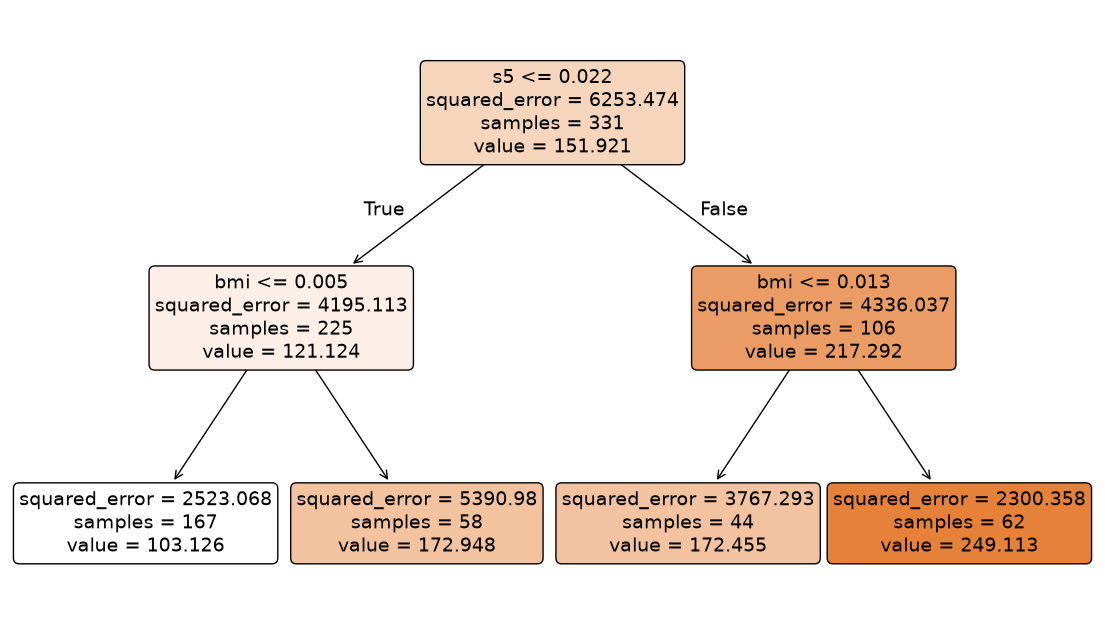

In [31]:
# Scrivi qui la tua soluzione
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor, plot_tree
import matplotlib.pyplot as plt

diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=0
)

listf=[1, 5, 20, 50]

for foglie in listf:
    albero = DecisionTreeRegressor(min_samples_leaf=foglie)
    albero.fit(X_train, y_train)

    print("Min samples leaf:", foglie)
    print("Numero di foglie:", albero.get_n_leaves())
    print("Score training:", albero.score(X_train, y_train))
    print("Score test:", albero.score(X_test, y_test))
    print("------------------------")

albero = DecisionTreeRegressor(max_depth=2, random_state=0)
albero.fit(X_train, y_train)

plt.figure(figsize=(14, 8))
plot_tree(albero, feature_names=diabetes.feature_names,filled=True, rounded=True)
plt.show()

#Nelle foglie di un albero di regressione, value rappresenta il valore medio della variabile da prevedere (y) 
# tra tutti i campioni di training che arrivano in quella foglia.

# 2.5 Metriche di classificazione

## Spiegazione teorica

L'accuratezza dice *quante* previsioni sono giuste, ma non *quali* errori fa il modello. In molti problemi gli errori non costano tutti uguale.

**Matrice di confusione (problema binario)**
Si sceglie una classe **positiva** (quella che vogliamo individuare: malato, frode, spam).
|  | Previsto negativo | Previsto positivo |
|---|---|---|
| **Reale negativo** | **TN** vero negativo | **FP** falso positivo (falso allarme) |
| **Reale positivo** | **FN** falso negativo (caso mancato) | **TP** vero positivo |
- In scikit-learn: **righe = classi reali, colonne = classi previste**, nell'ordine delle etichette (0 poi 1).
- Nella diagonale ci sono le previsioni corrette.

**Metriche derivate**
- **Accuratezza** = (TP + TN) / totale
- **Precision** = TP / (TP + FP) → "quando il modello dice *positivo*, quanto spesso ha ragione?"
- **Recall** (sensibilità) = TP / (TP + FN) → "di tutti i positivi reali, quanti ne trova?"
- **F1-score** = 2 × Precision × Recall / (Precision + Recall) → **media armonica** delle due.
  - La media armonica punisce gli squilibri: con precision 1.0 e recall 0.1 la media semplice sarebbe 0.55, l'F1 vale solo 0.18. Per avere F1 alto servono **entrambe** alte.

**Esempio numerico — screening su 100 pazienti, 10 malati**
- Il modello individua 8 malati su 10 (TP = 8, FN = 2) e segnala per errore 4 sani (FP = 4), TN = 86.
- Accuratezza = 94/100 = 0.94 · Precision = 8/12 = 0.67 · Recall = 8/10 = 0.80 · F1 = 0.73.
- Un modello "pigro" che dice sempre "sano" ha accuratezza **0.90** ma recall **0**: non trova nessun malato. Ecco perché l'accuratezza inganna con le **classi sbilanciate** (una classe molto più frequente delle altre).

**Quale metrica privilegiare**
- **Recall** quando i falsi negativi sono gravi: diagnosi, frodi, guasti di sicurezza (meglio un falso allarme che un caso mancato).
- **Precision** quando i falsi positivi sono costosi: filtro spam che sposta email importanti, campagne con costo per contatto.
- **F1** quando servono entrambe o le classi sono sbilanciate.

**Problemi multiclasse**
- Ogni classe viene trattata a turno come "positiva" contro tutte le altre: si ottengono precision, recall e F1 **per classe**.
- **Support:** numero di campioni reali di quella classe nel test set.
- **Macro avg:** media semplice delle metriche delle classi (ogni classe conta uguale).
- **Weighted avg:** media pesata per il support (le classi più numerose contano di più).

**Strumenti di scikit-learn**
- `confusion_matrix(y_true, y_pred, labels=None)`; `ConfusionMatrixDisplay` per disegnarla (`normalize="true"` mostra le percentuali per riga).
- `precision_score`, `recall_score`, `f1_score` con `pos_label` (classe positiva nei problemi binari) o `average="macro"/"weighted"` nei multiclasse.
- `classification_report(y_true, y_pred, target_names=..., digits=2, output_dict=False, zero_division=...)`: tabella con tutte le metriche. `zero_division` decide cosa restituire quando una divisione è per zero (es. il modello non prevede mai una classe, quindi TP + FP = 0).

**Split stratificato**
- `train_test_split(..., stratify=y)` mantiene in training e test le **stesse proporzioni** di classi del dataset originale.
- Con classi sbilanciate o pochi dati, uno split casuale potrebbe lasciare nel test pochissimi (o zero) campioni della classe rara.

## Esempi teorici di utilizzo

- **Screening medico:** si accettano più falsi allarmi (precision più bassa) pur di non perdere malati (recall alta); i casi positivi vengono poi verificati con esami più precisi.
- **Filtro antispam:** una mail importante finita nello spam (falso positivo) è grave; si privilegia la precision.
- **Frodi su carte (0.1% di transazioni fraudolente):** un modello che dice sempre "legittima" ha accuratezza 99.9% ed è inutile; si guardano recall e F1 sulla classe frode.
- **Riconoscimento di 10 cifre:** il report per classe mostra quali cifre il modello confonde (es. 3 con 8) e la matrice di confusione indica esattamente quali scambi avvengono.

## Esempi di codice

### Base
Cosa mostra: matrice di confusione e metriche calcolate a mano e con scikit-learn su un piccolo esempio.

In [ ]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score, accuracy_score

y_vero     = [1, 0, 1, 1, 0, 0, 1, 0, 0, 1]   # 1 = frode, 0 = transazione legittima
y_previsto = [1, 0, 0, 1, 0, 1, 1, 0, 0, 0]

tn, fp, fn, tp = confusion_matrix(y_vero, y_previsto).ravel()   # ordine: TN, FP, FN, TP
print(confusion_matrix(y_vero, y_previsto))     # righe = reale, colonne = previsto
print(f"TP={tp} TN={tn} FP={fp} FN={fn}")

print("Precision manuale:", tp / (tp + fp), "| sklearn:", precision_score(y_vero, y_previsto))
print("Recall manuale:   ", tp / (tp + fn), "| sklearn:", recall_score(y_vero, y_previsto))
print("F1:", round(f1_score(y_vero, y_previsto), 3), "| Accuratezza:", accuracy_score(y_vero, y_previsto))

- `ravel()` "appiattisce" la matrice 2×2 in quattro numeri nell'ordine TN, FP, FN, TP.
- Il modello trova 3 frodi su 5 (recall 0.6) e quando segnala una frode ha ragione 3 volte su 4 (precision 0.75).
- Di default la classe positiva è `1` (`pos_label=1`).

### Intermedio
Cosa mostra: il report completo su un dataset reale e l'importanza di scegliere la classe positiva giusta.

In [ ]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, recall_score

data = load_breast_cancer()
print(data.target_names)          # ['malignant' 'benign'] -> 0 = maligno, 1 = benigno!

X_train, X_test, y_train, y_test = train_test_split(
    data.data, data.target, test_size=0.25, random_state=42, stratify=data.target)   # proporzioni preservate

scaler = StandardScaler().fit(X_train)
knn = KNeighborsClassifier(n_neighbors=5).fit(scaler.transform(X_train), y_train)
y_pred = knn.predict(scaler.transform(X_test))

print(classification_report(y_test, y_pred, target_names=data.target_names))
print("Recall sui MALIGNI:", round(recall_score(y_test, y_pred, pos_label=0), 3))   # la classe che ci interessa

- In questo dataset la classe 1 è "benigno": la recall di default misurerebbe quanti benigni troviamo, non quanti tumori maligni. `pos_label=0` corregge.
- Il report mostra precision, recall, F1 e support per ogni classe, più le medie macro e weighted.
- `stratify` garantisce che il test abbia la stessa percentuale di maligni del dataset completo.

### Avanzato
Cosa mostra: perché l'accuratezza inganna con classi sbilanciate, e come disegnare la matrice di confusione.

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, confusion_matrix

X, y = make_classification(n_samples=2000, weights=[0.95, 0.05], random_state=42)   # 5% di positivi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

pigro = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)   # prevede SEMPRE la classe 0
albero = DecisionTreeClassifier(max_depth=5, random_state=42).fit(X_train, y_train)

for nome, m in [("Dummy", pigro), ("Albero", albero)]:
    y_pred = m.predict(X_test)
    print(f"{nome:7s} accuracy={accuracy_score(y_test, y_pred):.3f} "
          f"recall={recall_score(y_test, y_pred, zero_division=0):.3f} "
          f"f1={f1_score(y_test, y_pred, zero_division=0):.3f}")

cm = confusion_matrix(y_test, albero.predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",              # annot: scrive i numeri nelle celle
            xticklabels=["neg", "pos"], yticklabels=["neg", "pos"])
plt.xlabel("Previsto"); plt.ylabel("Reale"); plt.title("Matrice di confusione - albero")
plt.show()

- `DummyClassifier` è un modello "finto" che ignora le feature: serve come **soglia minima** da battere.
- Il Dummy ha accuratezza ~0.95 ma recall 0: senza guardare altre metriche sembrerebbe un buon modello.
- `fmt="d"` stampa i numeri come interi; la heatmap rende immediato vedere dove si concentrano gli errori.
- In alternativa a seaborn: `ConfusionMatrixDisplay.from_predictions(y_test, y_pred)`.

## Esercizi

### Facile
Obiettivo: un modello di controllo qualità ha analizzato 200 pezzi: 15 difettosi reali, di cui 12 individuati; inoltre ha segnalato come difettosi 6 pezzi buoni. Calcola a mano TP, TN, FP, FN, accuratezza, precision, recall e F1, poi verifica i risultati con scikit-learn creando i vettori `y_vero` e `y_previsto`.

In [ ]:
# Scrivi qui la tua soluzione


### Medio
Obiettivo: su `load_digits()` addestra un `DecisionTreeClassifier(max_depth=8)` con split stratificato. Stampa il `classification_report`, disegna la matrice di confusione con `ConfusionMatrixDisplay` e individua le due cifre confuse più spesso tra loro.

In [ ]:
# Scrivi qui la tua soluzione


### Difficile
Obiettivo: genera con `make_classification` un dataset con il 3% di positivi. Confronta `DummyClassifier`, KNN (con scaling corretto) e `DecisionTreeClassifier` su accuracy, precision, recall e F1 della classe positiva. Poi usa `predict_proba` dell'albero o del KNN e prova soglie di decisione diverse da 0.5 (0.3, 0.2, 0.1): come cambiano precision e recall? Quale soglia sceglieresti per un sistema antifrode e perché?

In [ ]:
# Scrivi qui la tua soluzione
